# Augmentation: oversample the minority classes in train

Run after `preprocessing.ipynb`. This notebook writes synthetic copies of training maps to `data/processed/train_aug/<class>/` and appends one row per copy to `manifest.csv`:
- `variant = "augmented"`
- `source_id` = the map's kept scan, which is the image the copy was made from
- `aug_params` = exactly what was applied

Rescans from `preprocessing.ipynb` (real scans of the same map from other libraries) already count as extra training samples, so this notebook only fills the gap that remains. Val and test are never touched. **Safe to re-run:** the previous augmentation is replaced, so the manifest never double-counts.

## 1. Settings
**How many copies.** Each class is topped up toward `TARGET_BALANCE` x the largest class, counting kept scans plus rescans. No map ever gets more than `MAX_COPIES_PER_MAP` extra samples, rescans and synthetic copies combined. Many near-copies of one floor plan teach the classifier that floor plan, not "Small". Copies go first to the maps with the fewest samples so far, so a map that already has 4 rescans gets no synthetic copies. Close whatever gap remains with `class_weight="balanced"` in the classifiers.

Every class, Large included, also gets synthetic copies for at least `MIN_AUG_FRACTION` of its maps. Otherwise augmentation artifacts (slight resampling blur, tilted borders) would only ever appear in the minority classes and become a shortcut for predicting them.

**Transforms** all preserve apparent scale: flips, a small tilt, a small zoom and shift, and contrast/brightness changes. Large zooms are avoided because how zoomed-in a map looks is exactly what we're classifying.

In [1]:
import json
import os
import shutil
import time
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

In [2]:
# ---- Paths (same layout as preprocessing.ipynb) -------------------------------------
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()), None)
assert ROOT is not None, "Open this notebook from inside the 281project repo"
OUT_DIR = ROOT / "data" / "processed"
MANIFEST = OUT_DIR / "manifest.csv"
AUG_DIR = OUT_DIR / "train_aug"
assert MANIFEST.exists(), "Run preprocessing.ipynb first"
OUTPUT_EXT = json.loads((OUT_DIR / "preprocess_config.json").read_text())["output_ext"]
CLASS_NAMES = {0: "small", 1: "medium", 2: "large"}
N_WORKERS = os.cpu_count() or 4
SEED = 281

# ---- How many copies ---------------------------------------------------------------
TARGET_BALANCE = 1.0        # aim each class at this fraction of the largest class's train count
MAX_COPIES_PER_MAP = 4      # cap on extra samples per map, rescans + synthetic copies combined
MIN_AUG_FRACTION = 0.25     # every class gets synthetic copies for at least this fraction of its maps

# ---- Transforms --------------------------------------------------------------------
P_HFLIP = 0.5
P_VFLIP = 0.5               # map orientation says nothing about scale
MAX_ROTATE_DEG = 5.0        # small tilt, like a crooked scan
SCALE_RANGE = (0.93, 1.07)  # small zoom only
MAX_TRANSLATE = 0.04        # shift, as a fraction of width / height
CONTRAST = 0.15             # factor drawn from [1 - CONTRAST, 1 + CONTRAST]
BRIGHTNESS = 0.10           # factor drawn from [1 - BRIGHTNESS, 1 + BRIGHTNESS] (paper tone, scan exposure)

## 2. Helpers
The same `parallel_map` and `border_color` as in `preprocessing.ipynb`, copied so this notebook runs on its own.

In [3]:
def parallel_map(fn, items, desc="working"):
    """fn over items on a thread pool, results in order, with a progress line."""
    items, out, t0 = list(items), [], time.time()
    step = max(1, len(items) // 20)
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        for i, result in enumerate(pool.map(fn, items), 1):
            out.append(result)
            if i % step == 0 or i == len(items):
                print(f"\r{desc}: {i}/{len(items)} ({time.time() - t0:.0f}s)", end="")
    print()
    return out


def border_color(img, frac=0.03):
    """Median color of the outer `frac` of the image - an estimate of the paper color."""
    h, w = img.shape[:2]
    b = max(1, int(min(h, w) * frac))
    edges = np.concatenate([img[:b].reshape(-1, 3), img[-b:].reshape(-1, 3),
                            img[:, :b].reshape(-1, 3), img[:, -b:].reshape(-1, 3)])
    return tuple(int(v) for v in np.median(edges, axis=0))

## 3. Load the manifest
`train` holds one row per training map (its kept scan), plus a count of how many rescans that map already has. Rows from a previous augmentation run are dropped here, in memory only; the old files are deleted in section 6, right before the new ones are written.

In [4]:
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
assert "variant" in manifest.columns, "manifest.csv is from an older run - re-run preprocessing.ipynb"
n_old = int((manifest["variant"] == "augmented").sum())
base = manifest[manifest["variant"] != "augmented"].copy()  # kept scans + rescans, all splits

train = (base[(base["split"] == "train") & (base["variant"] == "original")]
           .sort_values("image_id").reset_index(drop=True))
rescans_per_map = base[base["variant"] == "rescan"].groupby("source_id").size()
train["rescans"] = train["image_id"].map(rescans_per_map).fillna(0).astype(int)

print(f"{len(train)} train maps, which already have {train['rescans'].sum()} rescans between them; "
      f"{n_old} augmented rows from a previous run will be replaced")

1376 train maps, which already have 402 rescans between them; 0 augmented rows from a previous run will be replaced


## 4. Plan the copies
For each class, with `have` = kept scans + rescans and `maps` = number of maps:

`extra = max(TARGET_BALANCE * have_of_largest_class - have, MIN_AUG_FRACTION * maps)`

The extra copies are then handed out by **water-filling**: each one goes to a map with the fewest samples so far (ties broken at random), and no map goes past 1 + `MAX_COPIES_PER_MAP`. If every map hits the cap first, the class simply stays short.

In [5]:
def water_fill(current, limit, extra, rng):
    """Add `extra` samples, always to the maps with the fewest so far, never above `limit`."""
    total = current.copy()
    while extra > 0:
        open_ = np.flatnonzero(total < limit)
        if len(open_) == 0:
            break                                   # every map is at the cap
        lowest = open_[total[open_] == total[open_].min()]
        if extra >= len(lowest):
            total[lowest] += 1                      # raise the whole lowest level by one
            extra -= len(lowest)
        else:
            total[rng.choice(lowest, size=extra, replace=False)] += 1
            extra = 0
    return total - current


def plan_copies(train, rng):
    """Number of synthetic copies to make of each train map."""
    have = train.groupby("label").size() + train.groupby("label")["rescans"].sum()
    n_max = int(have.max())
    rescans = train["rescans"].to_numpy()
    copies = np.zeros(len(train), dtype=int)
    for label, idx in train.groupby("label").indices.items():
        current = 1 + rescans[idx]                  # samples each map already has
        extra = max(int(round(TARGET_BALANCE * n_max)) - int(current.sum()),
                    int(round(MIN_AUG_FRACTION * len(idx))))
        copies[idx] = water_fill(current, 1 + MAX_COPIES_PER_MAP, extra, rng)
    return copies


copies = plan_copies(train, np.random.default_rng(SEED))
plan = pd.DataFrame({"maps": train.groupby("label").size(),
                     "rescans": train.groupby("label")["rescans"].sum(),
                     "augmented": pd.Series(copies).groupby(train["label"]).sum()})
plan["total"] = plan.sum(axis=1)
plan["pct_of_train"] = (100 * plan["total"] / plan["total"].sum()).round(1)
plan.index = plan.index.map(CLASS_NAMES).rename("class")
display(plan)

,maps,rescans,augmented,total,pct_of_train
class,,,,,
small,120,19,461,600,17.7
medium,251,109,895,1255,37.1
large,1005,274,251,1530,45.2


## 5. Transforms
Each copy draws its own parameters from a random generator seeded by (`SEED`, image ID, copy number). Results are therefore reproducible and don't depend on which thread runs first. Corners exposed by the tilt or shift are filled with the page's paper color instead of black.

In [6]:
def copy_rng(image_id, k):
    return np.random.default_rng([SEED, zlib.crc32(image_id.encode()), k])


def random_params(rng):
    return {
        "hflip": bool(rng.random() < P_HFLIP),
        "vflip": bool(rng.random() < P_VFLIP),
        "angle": round(float(rng.uniform(-MAX_ROTATE_DEG, MAX_ROTATE_DEG)), 2),
        "scale": round(float(rng.uniform(*SCALE_RANGE)), 3),
        "tx": round(float(rng.uniform(-MAX_TRANSLATE, MAX_TRANSLATE)), 3),
        "ty": round(float(rng.uniform(-MAX_TRANSLATE, MAX_TRANSLATE)), 3),
        "contrast": round(float(rng.uniform(1 - CONTRAST, 1 + CONTRAST)), 3),
        "brightness": round(float(rng.uniform(1 - BRIGHTNESS, 1 + BRIGHTNESS)), 3),
    }


def apply_augmentation(img, p):
    h, w = img.shape[:2]
    fill = border_color(img)
    if p["hflip"]:
        img = img[:, ::-1]
    if p["vflip"]:
        img = img[::-1]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), p["angle"], p["scale"])  # tilt + zoom about the center
    M[0, 2] += p["tx"] * w
    M[1, 2] += p["ty"] * h
    img = cv2.warpAffine(np.ascontiguousarray(img), M, (w, h), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=fill)
    f = img.astype(np.float32)
    mean = f.mean()
    f = ((f - mean) * p["contrast"] + mean) * p["brightness"]
    return np.clip(f, 0, 255).astype(np.uint8)


def make_copy(src, dst, image_id, k):
    """Write augmented copy k of one image. Returns the parameters used, or an error message."""
    try:
        p = random_params(copy_rng(image_id, k))
        with Image.open(src) as im:
            img = np.asarray(im.convert("RGB"))
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        Image.fromarray(apply_augmentation(img, p)).save(dst)
        return p
    except Exception as e:
        return f"{Path(src).name}: {e!r}"

Preview before anything is written: a Small training map next to four random copies.

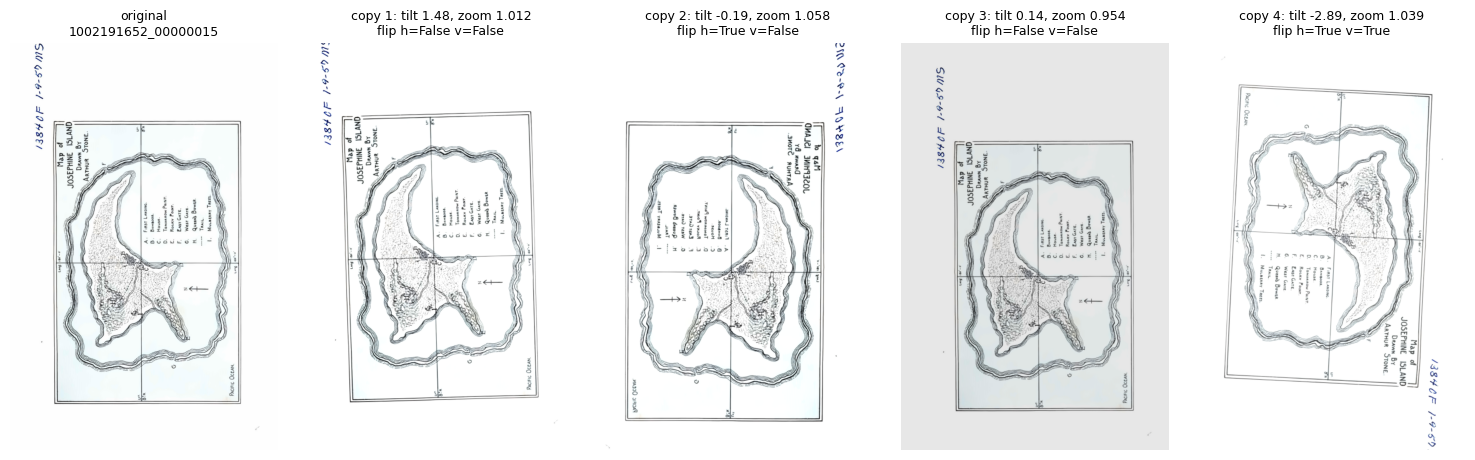

In [7]:
sample = train[train["label"] == 0].iloc[0]
img = np.asarray(Image.open(OUT_DIR / sample["path"]).convert("RGB"))
fig, axes = plt.subplots(1, 5, figsize=(15, 4.5))
axes[0].imshow(img)
axes[0].set_title(f"original\n{sample['image_id']}", fontsize=9)
for k, ax in enumerate(axes[1:], 1):
    p = random_params(copy_rng(sample["image_id"], k))
    ax.imshow(apply_augmentation(img, p))
    ax.set_title(f"copy {k}: tilt {p['angle']}, zoom {p['scale']}\n"
                 f"flip h={p['hflip']} v={p['vflip']}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Generate copies and update the manifest
Deletes the old `train_aug/` folder, writes the new copies, then saves the manifest. The save goes through a temporary file, so an interrupted run can't leave a half-written manifest.

Copies and rescans keep their map's `group_id` and `source_id`. If you ever cross-validate inside train, split folds by `group_id` (for example with `GroupKFold`) so samples of one map never sit on both sides of a fold.

In [8]:
shutil.rmtree(AUG_DIR, ignore_errors=True)

jobs, rows = [], []
for i, row in train.iterrows():
    for k in range(1, copies[i] + 1):
        new_id = f"{row['image_id']}__aug{k:02d}"
        rel = f"train_aug/{row['label_name']}/{new_id}{OUTPUT_EXT}"
        jobs.append((OUT_DIR / row["path"], OUT_DIR / rel, row["image_id"], k))
        rows.append({**row.to_dict(), "image_id": new_id, "path": rel, "variant": "augmented"})

results = parallel_map(lambda job: make_copy(*job), jobs, "augmenting")
errors = [r for r in results if isinstance(r, str)]
if errors:
    print(f"WARNING: {len(errors)} copies failed and are left out:", *errors[:10], sep="\n  ")
aug = pd.DataFrame([{**row, "aug_params": json.dumps(res, sort_keys=True)}
                    for row, res in zip(rows, results) if isinstance(res, dict)],
                   columns=base.columns)

out = pd.concat([base, aug], ignore_index=True)
tmp = MANIFEST.with_suffix(".csv.tmp")
out.to_csv(tmp, index=False)
os.replace(tmp, MANIFEST)
print(f"Wrote {len(aug)} copies to {AUG_DIR} and updated {MANIFEST.name}")

augmenting: 1607/1607 (17s)
Wrote 1607 copies to /home/uselessbian/281/281project/data/processed/train_aug and updated manifest.csv


## 7. Summary
The train split after augmentation, by variant. `augment_config.json` records the settings used.

In [9]:
tr = out[out["split"] == "train"]
summary = (pd.crosstab(tr["label"].map(CLASS_NAMES), tr["variant"])
             .reindex(index=list(CLASS_NAMES.values()), columns=["original", "rescan", "augmented"], fill_value=0)
             .rename_axis(index="class", columns=None))
summary["total"] = summary.sum(axis=1)
summary["pct_of_train"] = (100 * summary["total"] / summary["total"].sum()).round(1)
display(summary)
print(f"Most samples of any one map: {tr.groupby('source_id').size().max()} (cap is {1 + MAX_COPIES_PER_MAP})")

config = {
    "seed": SEED, "target_balance": TARGET_BALANCE, "max_copies_per_map": MAX_COPIES_PER_MAP,
    "min_aug_fraction": MIN_AUG_FRACTION, "p_hflip": P_HFLIP, "p_vflip": P_VFLIP,
    "max_rotate_deg": MAX_ROTATE_DEG, "scale_range": SCALE_RANGE, "max_translate": MAX_TRANSLATE,
    "contrast": CONTRAST, "brightness": BRIGHTNESS, "n_augmented": len(aug),
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(OUT_DIR / "augment_config.json").write_text(json.dumps(config, indent=2))
print("Saved augment_config.json")

,original,rescan,augmented,total,pct_of_train
class,,,,,
small,120,19,461,600,17.7
medium,251,109,895,1255,37.1
large,1005,274,251,1530,45.2


Most samples of any one map: 5 (cap is 5)
Saved augment_config.json


## 8. Spot check
One random synthetic copy per class, next to the map it was made from.

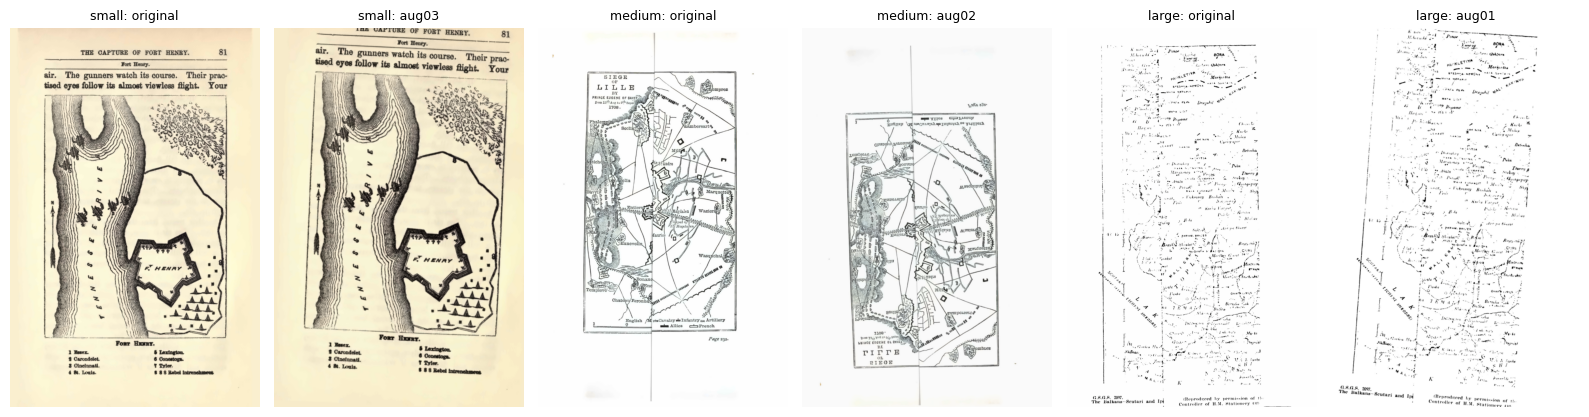

In [10]:
paths = base.set_index("image_id")["path"]
fig, axes = plt.subplots(1, 2 * len(CLASS_NAMES), figsize=(16, 4.5))
for c, (label, name) in enumerate(CLASS_NAMES.items()):
    left, right = axes[2 * c], axes[2 * c + 1]
    left.axis("off")
    right.axis("off")
    pool = aug[aug["label"] == label]
    if pool.empty:
        continue
    a = pool.sample(1, random_state=1).iloc[0]
    left.imshow(Image.open(OUT_DIR / paths[a["source_id"]]))
    left.set_title(f"{name}: original", fontsize=9)
    right.imshow(Image.open(OUT_DIR / a["path"]))
    right.set_title(f"{name}: {a['image_id'].split('__')[-1]}", fontsize=9)
plt.tight_layout()
plt.show()